<h1 align="center" style="color: blue;">Método de Newton-Raphson</h1>

El algoritmo formal del método de Newton establece las siguientes instrucciones paso a paso para encontrar la raíz de una función $f(x) = 0$:

**ENTRADA:** Aproximación inicial $p_0$; tolerancia $TOL$; número máximo de iteraciones $N_0$.
**SALIDA:** Solución aproximada $p$ o mensaje de falla.

1. Determine $i = 1$.
2. Mientras $i \le N_0$ haga los pasos 3–6.
3. Determine $p = p_0 - \frac{f(p_0)}{f'(p_0)}$. (Esta es la fórmula central para calcular $p_i$).
4. Si $\vert{}p - p_0\vert{} < TOL$ entonces SALIDA ($p$); PARE. (El procedimiento fue exitoso).
5. Determine $i = i + 1$.
6. Determine $p_0 = p$. (Actualice la aproximación).
7. SALIDA ('El método falló después de $N_0$ iteraciones'); PARE.
8. 

### 1. Importación de Librerías
Primero, importamos las herramientas necesarias. `numpy` para cálculos matemáticos, `matplotlib` para la gráfica, `pandas` para crear una tabla elegante, e ignoramos las advertencias de depreciación para mantener la libreta limpia.
    

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
import warnings

# Ocultamos la advertencia roja de Matplotlib
warnings.filterwarnings("ignore")


### 2. Definición de la Función y su Derivada
Implementamos el **Ejemplo 1** del material: 
Buscamos la raíz de $f(x) = \cos(x) - x$. 
Para el método de Newton, necesitamos su derivada: $f'(x) = -\sin(x) - 1$.


In [4]:
def f(x):
    return np.cos(x) - x

def df(x):
    return -np.sin(x) - 1
    

### 3. Algoritmo del Método de Newton
Aquí programamos el algoritmo paso a paso. Utilizamos una lista para guardar el historial de los puntos $p$ y otra para ir guardando los datos iterativos que luego mostraremos en una tabla de Pandas.


In [5]:
def metodo_newton(f, df, p0, TOL, N0):
    i = 1
    historial_p = [p0]
    datos_tabla = [] 
    
    while i <= N0:
        if df(p0) == 0:
            print("Derivada igual a cero. El método falla.")
            break
            
        p = p0 - f(p0) / df(p0)
        historial_p.append(p)
        error = abs(p - p0)
        
        # Guardar los datos de esta iteración para la tabla
        datos_tabla.append({
            "Iteración": i,
            "p_i": p,
            "Error |p - p0|": f"{error:.10e}"
        })
        
        if error < TOL:
            print(f"Procedimiento exitoso. La raíz aproximada es: {p:.10f}\n")
            df_resultados = pd.DataFrame(datos_tabla)
            display(df_resultados) 
            return p, historial_p
            
        i += 1
        p0 = p
        
    print(f"\nEl método falló después de {N0} iteraciones.")
    if datos_tabla:
        display(pd.DataFrame(datos_tabla))
    return None, historial_p
    

### 4. Ejecución del Método
Definimos los parámetros de entrada ($p_0 = \pi/4$, tolerancia de $10^{-8}$) y ejecutamos la función. Esto nos mostrará la tabla con los resultados.


In [6]:
# Parámetros de entrada
p0_inicial = np.pi / 4  # Aproximación inicial (pi/4)
TOL = 1e-8              # Tolerancia
N0 = 10                 # Número máximo de iteraciones

# Ejecución del algoritmo
raiz, iteraciones = metodo_newton(f, df, p0_inicial, TOL, N0)


Procedimiento exitoso. La raíz aproximada es: 0.7390851332



,Iteración,p_i,Error |p - p0|
0,1,0.739536,4.5862029882e-02
1,2,0.739085,4.5095540923e-04
2,3,0.739085,4.4890849149e-08
3,4,0.739085,4.4408920985e-16


### 5. Representación Gráfica
Por último, graficamos la función $f(x)$ junto con los puntos iterativos y las líneas tangentes para visualizar cómo el método converge rápidamente hacia la raíz (donde la curva azul cruza el eje X).


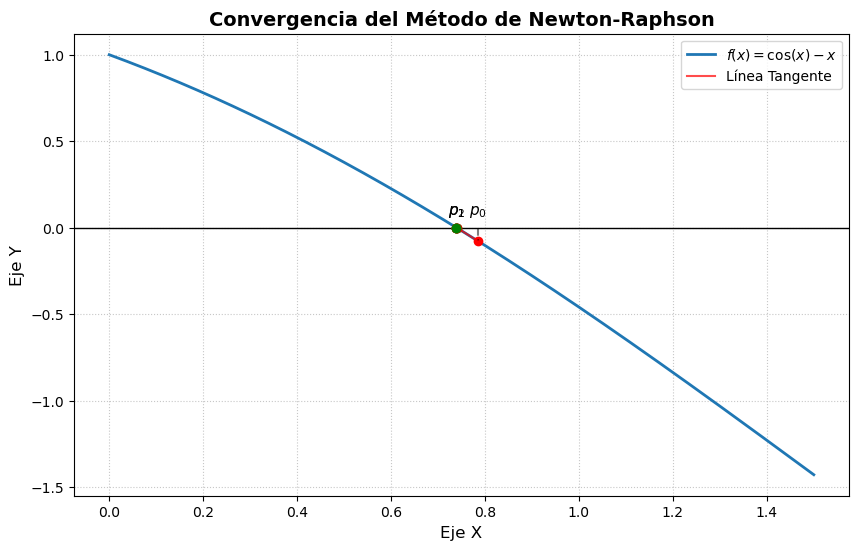

In [7]:
if iteraciones:
    x_vals = np.linspace(0, 1.5, 400)
    y_vals = f(x_vals)

    # Crear la figura
    plt.figure(figsize=(10, 6))

    # Graficar la función f(x) y el eje X (Usamos la 'r' cruda para evitar SyntaxWarning)
    plt.plot(x_vals, y_vals, label=r'$f(x) = \cos(x) - x$', color='#1f77b4', linewidth=2)
    plt.axhline(0, color='black', linewidth=1)

    # Graficar las aproximaciones y las líneas tangentes
    for k in range(len(iteraciones) - 1):
        pk = iteraciones[k]
        pk_next = iteraciones[k+1]
        fpk = f(pk)
        
        # Punto en la curva y punto proyectado en el eje X
        plt.plot(pk, fpk, 'ro')
        plt.plot(pk_next, 0, 'go')
        
        # Línea vertical punteada
        plt.plot([pk, pk], [0, fpk], 'k--', alpha=0.5)
        
        # Línea tangente
        plt.plot([pk, pk_next], [fpk, 0], 'r-', alpha=0.7, label='Línea Tangente' if k == 0 else "")
        
        # Etiquetas p_k
        if k < 3: 
            plt.text(pk, 0.05, f'$p_{k}$', ha='center', va='bottom', fontsize=11)

    plt.title("Convergencia del Método de Newton-Raphson", fontsize=14, fontweight='bold')
    plt.xlabel('Eje X', fontsize=12)
    plt.ylabel('Eje Y', fontsize=12)
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend()
    
    # Mostrar la gráfica
    plt.show()
    